In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

In [2]:
from pathlib import Path

DATA_DIR = next(
    (path for path in (Path('data/raw'), Path('../data/raw')) if path.is_dir()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError(f'Could not find data/raw from {Path.cwd()}')

sales = pd.read_csv(DATA_DIR / 'sales_train_evaluation.csv')
calendar = pd.read_csv(DATA_DIR / 'calendar.csv')
sell_prices = pd.read_csv(DATA_DIR / 'sell_prices.csv')

In [3]:
print("Sales shape:", sales.shape)
print("Calendar shape:", calendar.shape)
print("Sell prices shape:", sell_prices.shape)

Sales shape: (30490, 1947)
Calendar shape: (1969, 14)
Sell prices shape: (6841121, 4)


In [4]:
print("\nSales:")
print(sales.head())

print("\nCalendar:")
print(calendar.head())  

print("\nSell prices:")
print(sell_prices.head())


Sales:
                              id        item_id    dept_id   cat_id store_id  \
0  HOBBIES_1_001_CA_1_evaluation  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1   
1  HOBBIES_1_002_CA_1_evaluation  HOBBIES_1_002  HOBBIES_1  HOBBIES     CA_1   
2  HOBBIES_1_003_CA_1_evaluation  HOBBIES_1_003  HOBBIES_1  HOBBIES     CA_1   
3  HOBBIES_1_004_CA_1_evaluation  HOBBIES_1_004  HOBBIES_1  HOBBIES     CA_1   
4  HOBBIES_1_005_CA_1_evaluation  HOBBIES_1_005  HOBBIES_1  HOBBIES     CA_1   

  state_id  d_1  d_2  d_3  d_4  d_5  d_6  d_7  d_8  d_9  d_10  d_11  d_12  \
0       CA    0    0    0    0    0    0    0    0    0     0     0     0   
1       CA    0    0    0    0    0    0    0    0    0     0     0     0   
2       CA    0    0    0    0    0    0    0    0    0     0     0     0   
3       CA    0    0    0    0    0    0    0    0    0     0     0     0   
4       CA    0    0    0    0    0    0    0    0    0     0     0     0   

   d_13  d_14  d_15  d_16  d_17  d_18  d_19  d_2

         Understand sales dataset


In [5]:
print("Columns:")
print(sales.columns.tolist())

print("\nData types:")
print(sales.dtypes)

print("\nMissing values:")
print(sales.isnull().sum().sum())

print("\nUnique values:")
print("Items:", sales['item_id'].nunique())
print("Departments:", sales['dept_id'].nunique())
print("Categories:", sales['cat_id'].nunique())
print("Stores:", sales['store_id'].nunique())
print("States:", sales['state_id'].nunique())

Columns:
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd_1', 'd_2', 'd_3', 'd_4', 'd_5', 'd_6', 'd_7', 'd_8', 'd_9', 'd_10', 'd_11', 'd_12', 'd_13', 'd_14', 'd_15', 'd_16', 'd_17', 'd_18', 'd_19', 'd_20', 'd_21', 'd_22', 'd_23', 'd_24', 'd_25', 'd_26', 'd_27', 'd_28', 'd_29', 'd_30', 'd_31', 'd_32', 'd_33', 'd_34', 'd_35', 'd_36', 'd_37', 'd_38', 'd_39', 'd_40', 'd_41', 'd_42', 'd_43', 'd_44', 'd_45', 'd_46', 'd_47', 'd_48', 'd_49', 'd_50', 'd_51', 'd_52', 'd_53', 'd_54', 'd_55', 'd_56', 'd_57', 'd_58', 'd_59', 'd_60', 'd_61', 'd_62', 'd_63', 'd_64', 'd_65', 'd_66', 'd_67', 'd_68', 'd_69', 'd_70', 'd_71', 'd_72', 'd_73', 'd_74', 'd_75', 'd_76', 'd_77', 'd_78', 'd_79', 'd_80', 'd_81', 'd_82', 'd_83', 'd_84', 'd_85', 'd_86', 'd_87', 'd_88', 'd_89', 'd_90', 'd_91', 'd_92', 'd_93', 'd_94', 'd_95', 'd_96', 'd_97', 'd_98', 'd_99', 'd_100', 'd_101', 'd_102', 'd_103', 'd_104', 'd_105', 'd_106', 'd_107', 'd_108', 'd_109', 'd_110', 'd_111', 'd_112', 'd_113', 'd_114', 'd_115', '

In [6]:
print("First 10 rows:")
display(sales.head(10))

print("\nSales summary statistics:")
display(sales.iloc[:, 6:].describe().T.head(20))

print("\nTotal sales")
print("Total units sold:", sales.iloc[:, 6:].sum().sum())

print("\nZero sales percentage")
zero_pct = (sales.iloc[:, 6:] == 0).mean().mean() * 100
print(f"Zero sales percentage: {zero_pct:.2f}%")

First 10 rows:


id        item_id    dept_id   cat_id store_id  \
0  HOBBIES_1_001_CA_1_evaluation  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1   
1  HOBBIES_1_002_CA_1_evaluation  HOBBIES_1_002  HOBBIES_1  HOBBIES     CA_1   
2  HOBBIES_1_003_CA_1_evaluation  HOBBIES_1_003  HOBBIES_1  HOBBIES     CA_1   
3  HOBBIES_1_004_CA_1_evaluation  HOBBIES_1_004  HOBBIES_1  HOBBIES     CA_1   
4  HOBBIES_1_005_CA_1_evaluation  HOBBIES_1_005  HOBBIES_1  HOBBIES     CA_1   
5  HOBBIES_1_006_CA_1_evaluation  HOBBIES_1_006  HOBBIES_1  HOBBIES     CA_1   
6  HOBBIES_1_007_CA_1_evaluation  HOBBIES_1_007  HOBBIES_1  HOBBIES     CA_1   
7  HOBBIES_1_008_CA_1_evaluation  HOBBIES_1_008  HOBBIES_1  HOBBIES     CA_1   
8  HOBBIES_1_009_CA_1_evaluation  HOBBIES_1_009  HOBBIES_1  HOBBIES     CA_1   
9  HOBBIES_1_010_CA_1_evaluation  HOBBIES_1_010  HOBBIES_1  HOBBIES     CA_1   

  state_id  d_1  d_2  d_3  d_4  d_5  d_6  d_7  d_8  d_9  d_10  d_11  d_12  \
0       CA    0    0    0    0    0    0    0    0    0     0     0     0   
1       CA    0    0    0    0    0    0    0    0    0     0     0     0   
2       CA    0    0    0    0    0    0    0    0    0     0     0     0   
3       CA    0    0    0    0    0    0    0    0    0     0     0     0   
4       CA    0    0    0    0    0    0    0    0    0     0     0     0   
5       CA    0    0    0    0    0    0    0    0    0     0     0     0   
6       CA    0    0    0    0    0    0    0    0    0     0     0     0   
7       CA   12   15    0    0    0    4    6    5    7     0    13     2   
8       CA    2    0    7    3    0    2    3    9    0     0     4     3   
9       CA    0    0    1    0    0    0    0    0    0     0     0     0   

   d_13  d_14  d_15  d_16  d_17  d_18  d_19  d_20  d_21  d_22  d_23  d_24  \
0     0     0     0     0     0     0     0     0     0     0     0     0   
1     0     0     0     0     0     0     0     0     0     0     0     0   
2     0     0     0     0     0     0     0     0     0     0     0     0   
3     0     0     0     0     0     0     0     0     0     0     0     0   
4     0     0     0     0     0     0     0     0     0     0     0     0   
5     0     0     0     0     0     0     0     0     0     0     0     0   
6     0     0     0     0     0     0     0     0     0     0     0     0   
7     2    20     9     3     0     1     0     0     0    10     4     4   
8     1     0     4     4     1     2     0     1     1     5     2     2   
9     0     2     0     0     0     0     2     0     0     0     1     0   

   d_25  d_26  d_27  d_28  d_29  d_30  d_31  d_32  d_33  d_34  d_35  d_36  \
0     0     0     0     0     0     0     0     0     0     0     0     0   
1     0     0     0     0     0     0     0     0     0     0     0     0   
2     0     0     0     0     0     0     0     0     0     0     0     0   
3     0     0     0     0     0     0     0     0     0     0     0     0   
4     0     0     0     0     0     0     0     0     0     0     0     0   
5     0     0     0     0     0     0     0     0     0     0     0     0   
6     0     0     0     0     0     0     0     0     0     0     0     0   
7     2     6     2     0     0     0     0     0     0     0     0     0   
8     2     3     0     0     8     0     0     0     0     0     2     7   
9     0     0     0     0     0     0     0     0     0     0     0     0   

   d_37  d_38  d_39  d_40  d_41  d_42  d_43  d_44  d_45  d_46  d_47  d_48  \
0     0     0     0     0     0     0     0     0     0     0     0     0   
1     0     0     0     0     0     0     0     0     0     0     0     0   
2     0     0     0     0     0     0     0     0     0     0     0     0   
3     2     0     0     0     2     0     1     0     0     0     0     0   
4     0     0     0     0     0     0     0     0     0     0     0     0   
5     0     0     0     0     0     0     0     0     0     0     0     0   
6     0     0     0     0     0     0     0     0     0     0     


Sales summary statistics:


,count,mean,std,min,25%,50%,75%,max
d_1,30490.0,1.070220,5.126689,0.0,0.0,0.0,0.0,360.0
d_2,30490.0,1.041292,5.365468,0.0,0.0,0.0,0.0,436.0
d_3,30490.0,0.780026,3.667454,0.0,0.0,0.0,0.0,207.0
d_4,30490.0,0.833454,4.415141,0.0,0.0,0.0,0.0,323.0
d_5,30490.0,0.627944,3.379344,0.0,0.0,0.0,0.0,296.0
d_6,30490.0,0.958052,4.785947,0.0,0.0,0.0,0.0,314.0
d_7,30490.0,0.918662,5.059495,0.0,0.0,0.0,0.0,316.0
d_8,30490.0,1.244080,6.617729,0.0,0.0,0.0,0.0,370.0
d_9,30490.0,1.073663,5.917204,0.0,0.0,0.0,0.0,385.0
d_10,30490.0,0.838701,4.206199,0.0,0.0,0.0,0.0,353.0



Total sales
Total units sold: 66927173

Zero sales percentage
Zero sales percentage: 68.00%


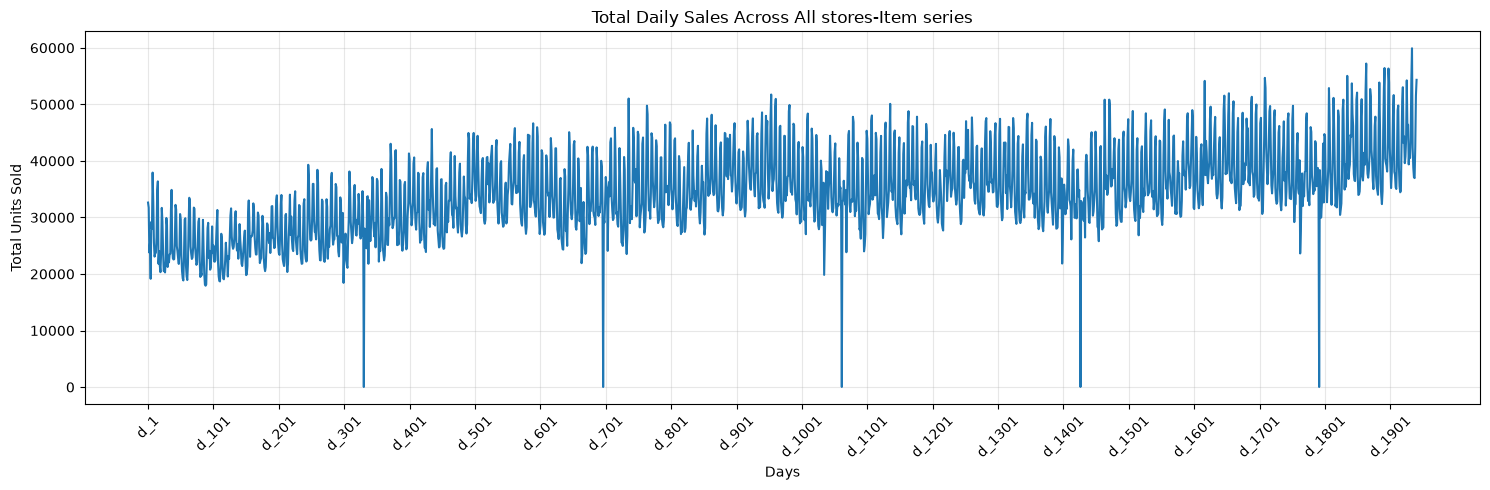

In [7]:
daily_sales = sales.iloc[:, 6:].sum(axis=0)

plt.figure(figsize=(15, 5))
plt.plot(daily_sales.values)

ticks = np.arange(0, len(daily_sales), 100)
labels=[daily_sales.index[i] for i in ticks]

plt.xticks(ticks, labels, rotation=45)
plt.title("Total Daily Sales Across All stores-Item series")
plt.xlabel("Days")
plt.ylabel("Total Units Sold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

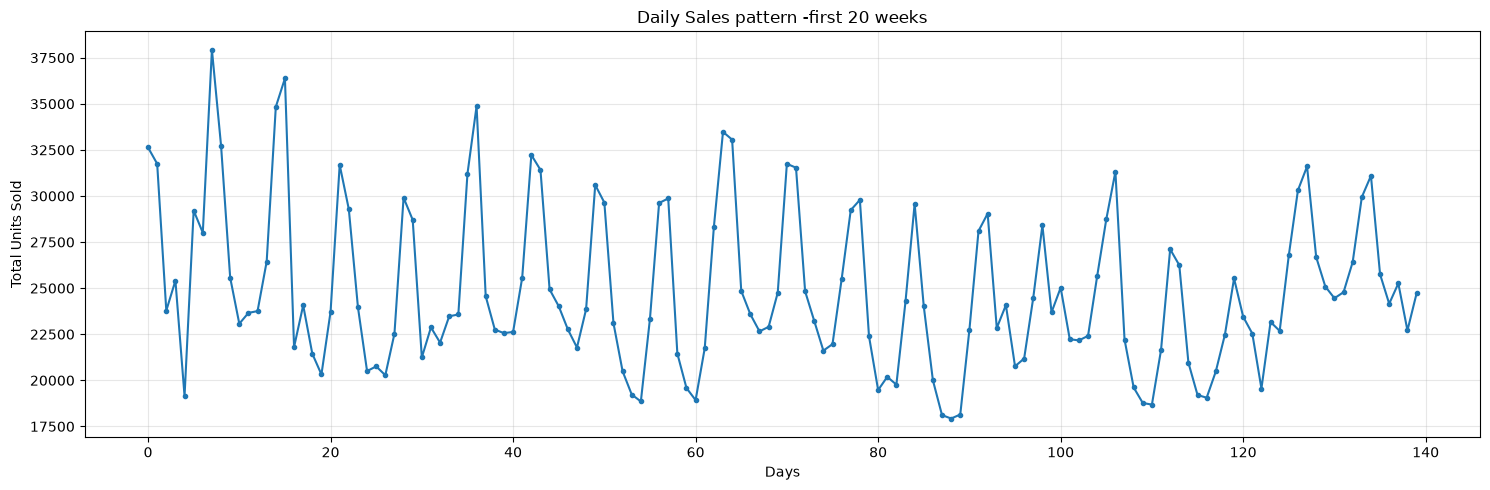

In [8]:
first_140=daily_sales.iloc[:140]

plt.figure(figsize=(15, 5))
plt.plot(first_140.values,marker="o",markersize=3)
plt.title("Daily Sales pattern -first 20 weeks")
plt.xlabel("Days")
plt.ylabel("Total Units Sold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
#  weekday sales by weekday position
weekday_pattern=first_140.groupby(np.arange(len(first_140))%7).mean()
print("\nAverage daily sales by weekday (0=Sunday, 6=Saturday):")
print(weekday_pattern)


Average daily sales by weekday (0=Sunday, 6=Saturday):
0    30640.45
1    29975.10
2    23424.45
3    22054.20
4    21327.35
5    21887.30
6    24739.45
dtype: float64


In [10]:
# understand caleder data

print("Calender columns:")
print(calendar.columns.tolist())

print("\nCalendar data types:")
print(calendar.dtypes)

print("\nCalendar missing values:")
print(calendar.isnull().sum().sort_values(ascending=False))

print("\nCalendar unique values:")
print("Dates:", calendar['date'].nunique())
print("Weekdays:", calendar['weekday'].nunique())
print("Years:", calendar['year'].nunique())


Calender columns:
['date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'd', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']

Calendar data types:
date              str
wm_yr_wk        int64
weekday           str
wday            int64
month           int64
year            int64
d                 str
event_name_1      str
event_type_1      str
event_name_2      str
event_type_2      str
snap_CA         int64
snap_TX         int64
snap_WI         int64
dtype: object

Calendar missing values:
event_type_2    1964
event_name_2    1964
event_name_1    1807
event_type_1    1807
date               0
wm_yr_wk           0
year               0
month              0
wday               0
weekday            0
d                  0
snap_CA            0
snap_TX            0
snap_WI            0
dtype: int64

Calendar unique values:
Dates: 1969
Weekdays: 7
Years: 6


In [11]:
print(calendar[["d", "date", "weekday", "month", "year"]].head(10))

print("\nFirst day:", calendar["date"].min())
print("\nLast day:", calendar["date"].max())

print("\nUnique day IDs:", calendar["d"].nunique())

      d        date    weekday  month  year
0   d_1  2011-01-29   Saturday      1  2011
1   d_2  2011-01-30     Sunday      1  2011
2   d_3  2011-01-31     Monday      1  2011
3   d_4  2011-02-01    Tuesday      2  2011
4   d_5  2011-02-02  Wednesday      2  2011
5   d_6  2011-02-03   Thursday      2  2011
6   d_7  2011-02-04     Friday      2  2011
7   d_8  2011-02-05   Saturday      2  2011
8   d_9  2011-02-06     Sunday      2  2011
9  d_10  2011-02-07     Monday      2  2011

First day: 2011-01-29

Last day: 2016-06-19

Unique day IDs: 1969


In [12]:
#  understand sales prices dataset

print("Columns:")
print(sell_prices.columns.tolist())

print("\nData types:")
print(sell_prices.dtypes)

print("\nMissing values:")
print(sell_prices.isnull().sum())

print("\nUnique values:")
print("Stores:", sell_prices['store_id'].nunique())
print("Items:", sell_prices['item_id'].nunique())
print("Weeks:", sell_prices['wm_yr_wk'].nunique())

print("\nPrice statistics:")
print(sell_prices['sell_price'].describe())

Columns:
['store_id', 'item_id', 'wm_yr_wk', 'sell_price']

Data types:
store_id          str
item_id           str
wm_yr_wk        int64
sell_price    float64
dtype: object

Missing values:
store_id      0
item_id       0
wm_yr_wk      0
sell_price    0
dtype: int64

Unique values:
Stores: 10
Items: 3049
Weeks: 282

Price statistics:
count    6.841121e+06
mean     4.410952e+00
std      3.408814e+00
min      1.000000e-02
25%      2.180000e+00
50%      3.470000e+00
75%      5.840000e+00
max      1.073200e+02
Name: sell_price, dtype: float64


In [13]:
example=sell_prices[
    (sell_prices['store_id'] == 'CA_1') &
    (sell_prices['item_id'] == 'HOBBIES_1_001')
]

display(example.head(10))

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26
5,CA_1,HOBBIES_1_001,11330,8.26
6,CA_1,HOBBIES_1_001,11331,8.26
7,CA_1,HOBBIES_1_001,11332,8.26
8,CA_1,HOBBIES_1_001,11333,8.26
9,CA_1,HOBBIES_1_001,11334,8.26


In [14]:
prices_changes=(
    sell_prices
    .sort_values(by=['store_id', 'item_id', 'wm_yr_wk'])
    .groupby(['store_id', 'item_id'])['sell_price']
    .nunique()
)

print("Total store-item combinations:",len(prices_changes))
print("Price never changes:",(prices_changes==1).sum())
print("Price changes at least once:",(prices_changes>1).sum())

print("\nPercentage:")
print(f"Price never changes:{(prices_changes==1).sum()/len(prices_changes)*100:.2f}%")
print(f"Price changes :{(prices_changes>1).mean()*100:.2f}%")

Total store-item combinations: 30490
Price never changes: 8247
Price changes at least once: 22243

Percentage:
Price never changes:27.05%
Price changes :72.95%


Data preprocessing


In [15]:
# Convert sales data from wide to long format without expanding identifier strings.

id_cols = ['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id']
day_cols = sales.columns[6:]

sales[id_cols] = sales[id_cols].astype('category')
sales[day_cols] = sales[day_cols].astype(np.uint16)

long_sales = sales.melt(
    id_vars=id_cols, var_name='d', value_name='sales'
)
long_sales['d'] = long_sales['d'].astype('category')
long_sales['sales'] = long_sales['sales'].astype('float32')

print("Shape:", long_sales.shape)
display(long_sales.head(10))

Shape: (59181090, 8)


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0.0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0.0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0.0
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0.0
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0.0
5,HOBBIES_1_006_CA_1_evaluation,HOBBIES_1_006,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0.0
6,HOBBIES_1_007_CA_1_evaluation,HOBBIES_1_007,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0.0
7,HOBBIES_1_008_CA_1_evaluation,HOBBIES_1_008,HOBBIES_1,HOBBIES,CA_1,CA,d_1,12.0
8,HOBBIES_1_009_CA_1_evaluation,HOBBIES_1_009,HOBBIES_1,HOBBIES,CA_1,CA,d_1,2.0
9,HOBBIES_1_010_CA_1_evaluation,HOBBIES_1_010,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0.0


In [16]:
#sales+calender

long_sales=long_sales.merge(calendar, on='d', how='left')
print("Shape after merging with calendar:", long_sales.shape)
display(long_sales.head(10))

Shape after merging with calendar: (59181090, 21)


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,weekday,wday,month,year,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0.0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0.0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0.0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0.0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0.0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0
5,HOBBIES_1_006_CA_1_evaluation,HOBBIES_1_006,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0.0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0
6,HOBBIES_1_007_CA_1_evaluation,HOBBIES_1_007,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0.0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0
7,HOBBIES_1_008_CA_1_evaluation,HOBBIES_1_008,HOBBIES_1,HOBBIES,CA_1,CA,d_1,12.0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0
8,HOBBIES_1_009_CA_1_evaluation,HOBBIES_1_009,HOBBIES_1,HOBBIES,CA_1,CA,d_1,2.0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0
9,HOBBIES_1_010_CA_1_evaluation,HOBBIES_1_010,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0.0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0


In [17]:
#sales+price

long_sales=long_sales.merge(
    sell_prices, on=['store_id', 'item_id', 'wm_yr_wk'], how='left'
)
print("Shape after merging with sell_prices:", long_sales.shape)
display(long_sales.head())

Shape after merging with sell_prices: (59181090, 22)


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,weekday,wday,month,year,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI,sell_price
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0.0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0,NaN
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0.0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0,NaN
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0.0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0,NaN
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0.0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0,NaN
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0.0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0,NaN


In [18]:
print("\nMissing values after merging:")
print(long_sales["sell_price"].isna().sum())

print("\nPrice coverage:")
print(long_sales["sell_price"].notna().mean() * 100)


Missing values after merging:
12299413

Price coverage:
79.21732600734458


In [19]:
missing_prices = long_sales[long_sales["sell_price"].isna()]
print("Missing price rows:",len(missing_prices))
print("\nMissing price by stores:")
display(missing_prices["store_id"].value_counts())
print("\nMissing price by items:")
display(missing_prices["item_id"].value_counts().head(10))

Missing price rows: 12299413

Missing price by stores:


store_id
CA_2    1556961
WI_1    1357342
WI_2    1271529
CA_4    1265551
TX_3    1180942
CA_3    1160796
WI_3    1146068
CA_1    1129842
TX_1    1120154
TX_2    1110228
Name: count, dtype: int64


Missing price by items:


item_id
FOODS_2_379        16030
FOODS_3_296        15596
HOUSEHOLD_1_242    15540
HOUSEHOLD_1_159    15379
HOUSEHOLD_1_308    15246
FOODS_2_253        15155
HOUSEHOLD_2_186    15078
FOODS_3_353        15036
HOUSEHOLD_1_489    14889
HOUSEHOLD_1_484    14882
Name: count, dtype: int64

In [20]:
missing_check=(
    long_sales[long_sales["sell_price"].isna()]
    .groupby(["store_id","item_id"])["date"]
    .agg(["min","max","count"])
    .sort_values("count", ascending=False)
)

display(missing_check.head(10))

,,min,max,count
store_id,item_id,,,
WI_1,HOUSEHOLD_1_386,2011-01-29,2016-02-12,1841
CA_2,HOUSEHOLD_1_405,2011-01-29,2016-02-12,1841
WI_2,HOUSEHOLD_1_020,2011-01-29,2016-02-12,1841
CA_4,HOUSEHOLD_1_400,2011-01-29,2016-02-12,1841
CA_3,HOUSEHOLD_1_278,2011-01-29,2016-02-12,1841
CA_2,HOUSEHOLD_1_311,2011-01-29,2016-02-12,1841
CA_1,FOODS_3_595,2011-01-29,2016-02-12,1841
CA_3,FOODS_3_595,2011-01-29,2016-02-12,1841
WI_2,HOUSEHOLD_1_400,2011-01-29,2016-01-29,1827


In [21]:
missing_price_mask = long_sales["sell_price"].isna()
missing_prices = long_sales.loc[missing_price_mask]

print("Missing-price rows:", len(missing_prices))

print("Zero sales among missing-price rows:")
print((missing_prices["sales"] == 0).mean() * 100)

print("\nNon-zero sales among missing-price rows:")
print((missing_prices["sales"] > 0).mean() * 100)

Missing-price rows: 12299413
Zero sales among missing-price rows:
100.0

Non-zero sales among missing-price rows:
0.0


In [22]:
print("SNAP columns:")
print([col for col in  calendar.columns if col.startswith("snap")])

print("\nSNAP values:")
for col in ["snap_CA","snap_TX","snap_WI"]:
    print(f"\n{col}:")
    print(calendar[col].value_counts())

SNAP columns:
['snap_CA', 'snap_TX', 'snap_WI']

SNAP values:

snap_CA:
snap_CA
0    1319
1     650
Name: count, dtype: int64

snap_TX:
snap_TX
0    1319
1     650
Name: count, dtype: int64

snap_WI:
snap_WI
0    1319
1     650
Name: count, dtype: int64


In [23]:
#o snap benefit is not available ,1 snap benefit available 

print("Missing d:",long_sales["d"].isna().sum())
print("Duplicate store-item-day rows:",
      long_sales.duplicated(subset=["store_id","item_id","d"]).sum())
print("Total rows:",len(long_sales))

Missing d: 0
Duplicate store-item-day rows: 0
Total rows: 59181090


In [24]:
# final missing value check after both merge
important_cols=[
    "item_id",
    "store_id",
    "state_id",
    "d",
    "date",
    "sales",
    "wm_yr_wk",
    "sell_price"
]
missing_summary=long_sales[important_cols].isnull().sum()

display(missing_summary)

item_id              0
store_id             0
state_id             0
d                    0
date                 0
sales                0
wm_yr_wk             0
sell_price    12299413
dtype: int64

Feature Enginering

In [25]:
print(long_sales["date"])

0           2011-01-29
1           2011-01-29
2           2011-01-29
3           2011-01-29
4           2011-01-29
               ...    
59181085    2016-05-22
59181086    2016-05-22
59181087    2016-05-22
59181088    2016-05-22
59181089    2016-05-22
Name: date, Length: 59181090, dtype: str


In [26]:
#convert date colums to datetime

long_sales["date"]=pd.to_datetime(long_sales["date"])

#check
print(long_sales["date"].dtype)
display(long_sales[["d","date"]].head())

datetime64[us]


,d,date
0,d_1,2011-01-29
1,d_1,2011-01-29
2,d_1,2011-01-29
3,d_1,2011-01-29
4,d_1,2011-01-29


In [27]:
# Preview a single series' previous-day sales without duplicating a full-data feature.
example = long_sales.loc[
    (long_sales["store_id"] == "CA_1")
    & (long_sales["item_id"] == "HOBBIES_1_001"),
    ["store_id", "item_id", "date", "sales"],
].copy()
example["lag_1"] = example["sales"].shift(1)

display(example.head(15))

,store_id,item_id,date,sales,lag_1
0,CA_1,HOBBIES_1_001,2011-01-29,0.0,NaN
30490,CA_1,HOBBIES_1_001,2011-01-30,0.0,0.0
60980,CA_1,HOBBIES_1_001,2011-01-31,0.0,0.0
91470,CA_1,HOBBIES_1_001,2011-02-01,0.0,0.0
121960,CA_1,HOBBIES_1_001,2011-02-02,0.0,0.0
152450,CA_1,HOBBIES_1_001,2011-02-03,0.0,0.0
182940,CA_1,HOBBIES_1_001,2011-02-04,0.0,0.0
213430,CA_1,HOBBIES_1_001,2011-02-05,0.0,0.0
243920,CA_1,HOBBIES_1_001,2011-02-06,0.0,0.0
274410,CA_1,HOBBIES_1_001,2011-02-07,0.0,0.0


all are nan beacuse which oneraw we see that is first day(2011-01-29) ha,first day to prious day is not available

In [28]:
import gc

# These raw/diagnostic dataframes are no longer needed after merging.
for name in ("missing_prices", "missing_price_mask", "sell_prices", "sales"):
    globals().pop(name, None)
gc.collect()

series_count = long_sales["id"].nunique()
if series_count == 0 or len(long_sales) % series_count:
    raise ValueError("long_sales must contain complete daily store-item blocks.")

panel_ids = long_sales["id"].cat.codes.to_numpy(copy=False)
panel_ids = panel_ids.reshape(-1, series_count)
if not np.all(panel_ids == panel_ids[0]):
    raise ValueError("Store-item ordering must be consistent across dates.")

for lag in [1, 7, 14, 28, 56]:
    long_sales[f"lag_{lag}"] = long_sales["sales"].shift(series_count * lag)

display(
    long_sales[
        ["store_id", "item_id", "date", "sales",
         "lag_1", "lag_7", "lag_14", "lag_28", "lag_56"]
    ].head(70)
)

,store_id,item_id,date,sales,lag_1,lag_7,lag_14,lag_28,lag_56
0,CA_1,HOBBIES_1_001,2011-01-29,0.0,NaN,NaN,NaN,NaN,NaN
1,CA_1,HOBBIES_1_002,2011-01-29,0.0,NaN,NaN,NaN,NaN,NaN
2,CA_1,HOBBIES_1_003,2011-01-29,0.0,NaN,NaN,NaN,NaN,NaN
3,CA_1,HOBBIES_1_004,2011-01-29,0.0,NaN,NaN,NaN,NaN,NaN
4,CA_1,HOBBIES_1_005,2011-01-29,0.0,NaN,NaN,NaN,NaN,NaN
5,CA_1,HOBBIES_1_006,2011-01-29,0.0,NaN,NaN,NaN,NaN,NaN
6,CA_1,HOBBIES_1_007,2011-01-29,0.0,NaN,NaN,NaN,NaN,NaN
7,CA_1,HOBBIES_1_008,2011-01-29,12.0,NaN,NaN,NaN,NaN,NaN
8,CA_1,HOBBIES_1_009,2011-01-29,2.0,NaN,NaN,NaN,NaN,NaN
9,CA_1,HOBBIES_1_010,2011-01-29,0.0,NaN,NaN,NaN,NaN,NaN


In [29]:
#Rolling featers based on previous sales

group_cols=["store_id","item_id"]

long_sales["roll_mean_7"]=(
    long_sales
    .groupby(group_cols)["sales"]
    .transform(lambda x:x.shift(1).rolling(7).mean())
)

long_sales["roll_std_7"]=(
    long_sales
    .groupby(group_cols)["sales"]
    .transform(lambda x:x.shift(1).rolling(7).std())
)
long_sales["roll_mean_28"]=(
    long_sales
    .groupby(group_cols)["sales"]
    .transform(lambda x:x.shift(1).rolling(28).mean())
)

long_sales["roll_std_28"]=(
    long_sales
    .groupby(group_cols)["sales"]
    .transform(lambda x:x.shift(1).rolling(28).std())
)

display(
    long_sales[
        ["store_id","item_id","date","sales",
         "roll_mean_7","roll_std_7",
         "roll_mean_28","roll_std_28"]
    ].head(40)
)

,store_id,item_id,date,sales,roll_mean_7,roll_std_7,roll_mean_28,roll_std_28
0,CA_1,HOBBIES_1_001,2011-01-29,0.0,NaN,NaN,NaN,NaN
1,CA_1,HOBBIES_1_002,2011-01-29,0.0,NaN,NaN,NaN,NaN
2,CA_1,HOBBIES_1_003,2011-01-29,0.0,NaN,NaN,NaN,NaN
3,CA_1,HOBBIES_1_004,2011-01-29,0.0,NaN,NaN,NaN,NaN
4,CA_1,HOBBIES_1_005,2011-01-29,0.0,NaN,NaN,NaN,NaN
5,CA_1,HOBBIES_1_006,2011-01-29,0.0,NaN,NaN,NaN,NaN
6,CA_1,HOBBIES_1_007,2011-01-29,0.0,NaN,NaN,NaN,NaN
7,CA_1,HOBBIES_1_008,2011-01-29,12.0,NaN,NaN,NaN,NaN
8,CA_1,HOBBIES_1_009,2011-01-29,2.0,NaN,NaN,NaN,NaN
9,CA_1,HOBBIES_1_010,2011-01-29,0.0,NaN,NaN,NaN,NaN


In [30]:
example=long_sales[
    (long_sales["store_id"]=="CA_1") &
    (long_sales["item_id"]=="HOBBIES_1_001")

].iloc[25:35]

display(
    example[
        ["date","sales","roll_mean_7","roll_std_7","roll_mean_28","roll_std_28"]
    ]
)

,date,sales,roll_mean_7,roll_std_7,roll_mean_28,roll_std_28
762250,2011-02-23,0.0,0.0,0.0,NaN,NaN
792740,2011-02-24,0.0,0.0,0.0,NaN,NaN
823230,2011-02-25,0.0,0.0,0.0,NaN,NaN
853720,2011-02-26,0.0,0.0,0.0,0.0,0.0
884210,2011-02-27,0.0,0.0,0.0,0.0,0.0
914700,2011-02-28,0.0,0.0,0.0,0.0,0.0
945190,2011-03-01,0.0,0.0,0.0,0.0,0.0
975680,2011-03-02,0.0,0.0,0.0,0.0,0.0
1006170,2011-03-03,0.0,0.0,0.0,0.0,0.0
1036660,2011-03-04,0.0,0.0,0.0,0.0,0.0


In [31]:
#calender based features
long_sales["day_of_week"]=long_sales["date"].dt.dayofweek
long_sales["day_of_month"]=long_sales["date"].dt.day
long_sales["week_of_year"]=long_sales["date"].dt.isocalendar().week.astype("int16")
long_sales["month_num"]=long_sales["date"].dt.month
long_sales["year_num"]=long_sales["date"].dt.year

display(
    long_sales[
        ["date","day_of_week","day_of_month","week_of_year","month_num","year_num"]
    ].head(10)
)





,date,day_of_week,day_of_month,week_of_year,month_num,year_num
0,2011-01-29,5,29,4,1,2011
1,2011-01-29,5,29,4,1,2011
2,2011-01-29,5,29,4,1,2011
3,2011-01-29,5,29,4,1,2011
4,2011-01-29,5,29,4,1,2011
5,2011-01-29,5,29,4,1,2011
6,2011-01-29,5,29,4,1,2011
7,2011-01-29,5,29,4,1,2011
8,2011-01-29,5,29,4,1,2011
9,2011-01-29,5,29,4,1,2011


In [32]:
#check event information

event_cols=["event_name_1","event_type_1","event_name_2","event_type_2"]

for col in event_cols:
    print(f"\n{col}:")
    print(calendar[col].value_counts(dropna=False).head(10))


event_name_1:
event_name_1
NaN              1807
SuperBowl           6
ValentinesDay       6
PresidentsDay       6
LentStart           6
LentWeek2           6
StPatricksDay       6
Purim End           6
Pesach End          6
Mother's day        6
Name: count, dtype: int64

event_type_1:
event_type_1
NaN          1807
Religious      55
National       52
Cultural       37
Sporting       18
Name: count, dtype: int64

event_name_2:
event_name_2
NaN               1964
Father's day         2
Easter               1
Cinco De Mayo        1
OrthodoxEaster       1
Name: count, dtype: int64

event_type_2:
event_type_2
NaN          1964
Cultural        4
Religious       1
Name: count, dtype: int64


In [33]:
#event indicater

long_sales["is_event"]=(
    long_sales["event_name_1"].notna() |
    long_sales["event_name_2"].notna()
).astype("int8")

print(long_sales["is_event"].value_counts())

display(
    long_sales[
        ["date","event_name_1","event_name_2","is_event"]
    ].head(20)
)

is_event
0    54363670
1     4817420
Name: count, dtype: int64


,date,event_name_1,event_name_2,is_event
0,2011-01-29,NaN,NaN,0
1,2011-01-29,NaN,NaN,0
2,2011-01-29,NaN,NaN,0
3,2011-01-29,NaN,NaN,0
4,2011-01-29,NaN,NaN,0
5,2011-01-29,NaN,NaN,0
6,2011-01-29,NaN,NaN,0
7,2011-01-29,NaN,NaN,0
8,2011-01-29,NaN,NaN,0
9,2011-01-29,NaN,NaN,0


#0 it has no any event 1 means event ha

In [34]:
long_sales["snap"] = np.select(
    [
        long_sales["state_id"] == "CA",
        long_sales["state_id"] == "TX",
        long_sales["state_id"] == "WI",
    ],
    [
        long_sales["snap_CA"],
        long_sales["snap_TX"],
        long_sales["snap_WI"],
    ],
    default=0,
).astype("int8")

print(long_sales["snap"].value_counts())

display(
    long_sales[
        ["state_id","date","snap_CA","snap_TX","snap_WI","snap"]
    ].head(10)
)

snap
0    39667490
1    19513600
Name: count, dtype: int64


,state_id,date,snap_CA,snap_TX,snap_WI,snap
0,CA,2011-01-29,0,0,0,0
1,CA,2011-01-29,0,0,0,0
2,CA,2011-01-29,0,0,0,0
3,CA,2011-01-29,0,0,0,0
4,CA,2011-01-29,0,0,0,0
5,CA,2011-01-29,0,0,0,0
6,CA,2011-01-29,0,0,0,0
7,CA,2011-01-29,0,0,0,0
8,CA,2011-01-29,0,0,0,0
9,CA,2011-01-29,0,0,0,0


In [35]:
# Rows are already chronological within each store-item series; avoid sorting the full dataframe.

# Previous available price
series_count = long_sales["id"].nunique()
if series_count == 0 or len(long_sales) % series_count:
    raise ValueError("long_sales must contain complete daily store-item blocks.")

first_day_ids = long_sales["id"].iloc[:series_count].to_numpy()
second_day_ids = long_sales["id"].iloc[series_count:2 * series_count].to_numpy()
if not np.array_equal(first_day_ids, second_day_ids):
    raise ValueError("Store-item ordering must be consistent across dates.")

previous_price = long_sales["sell_price"].shift(series_count)
previous_price.iloc[:series_count] = np.nan
long_sales["prev_price"] = previous_price

# Price change amount
long_sales["price_change"] = (
    long_sales["sell_price"] - long_sales["prev_price"]
)

# Price change percentage
long_sales["price_change_pct"] = (
    long_sales["price_change"] / long_sales["prev_price"]
) * 100

display(
    long_sales[
        ["store_id", "item_id", "date", "sell_price",
         "prev_price", "price_change", "price_change_pct"]
    ].head(20)
)

,store_id,item_id,date,sell_price,prev_price,price_change,price_change_pct
0,CA_1,HOBBIES_1_001,2011-01-29,NaN,NaN,NaN,NaN
1,CA_1,HOBBIES_1_002,2011-01-29,NaN,NaN,NaN,NaN
2,CA_1,HOBBIES_1_003,2011-01-29,NaN,NaN,NaN,NaN
3,CA_1,HOBBIES_1_004,2011-01-29,NaN,NaN,NaN,NaN
4,CA_1,HOBBIES_1_005,2011-01-29,NaN,NaN,NaN,NaN
5,CA_1,HOBBIES_1_006,2011-01-29,NaN,NaN,NaN,NaN
6,CA_1,HOBBIES_1_007,2011-01-29,NaN,NaN,NaN,NaN
7,CA_1,HOBBIES_1_008,2011-01-29,0.46,NaN,NaN,NaN
8,CA_1,HOBBIES_1_009,2011-01-29,1.56,NaN,NaN,NaN
9,CA_1,HOBBIES_1_010,2011-01-29,3.17,NaN,NaN,NaN


In [36]:
long_sales["is_price_change"]=(
    long_sales["price_change"]!=0
).astype("int8")

display(
    long_sales[
        ["date","sell_price","prev_price","price_change","price_change_pct","is_price_change"]
    ].head(20)
)

,date,sell_price,prev_price,price_change,price_change_pct,is_price_change
0,2011-01-29,NaN,NaN,NaN,NaN,1
1,2011-01-29,NaN,NaN,NaN,NaN,1
2,2011-01-29,NaN,NaN,NaN,NaN,1
3,2011-01-29,NaN,NaN,NaN,NaN,1
4,2011-01-29,NaN,NaN,NaN,NaN,1
5,2011-01-29,NaN,NaN,NaN,NaN,1
6,2011-01-29,NaN,NaN,NaN,NaN,1
7,2011-01-29,0.46,NaN,NaN,NaN,1
8,2011-01-29,1.56,NaN,NaN,NaN,1
9,2011-01-29,3.17,NaN,NaN,NaN,1


In [37]:
# Demand / intermittency features

group_cols = ["store_id", "item_id"]

# Previous 7 and 28 days' zero-sales ratios
long_sales["zero_ratio_7"] = (
    long_sales
    .groupby(group_cols)["sales"]
    .transform(lambda values: values.shift(1).eq(0).rolling(7).mean())
)

long_sales["zero_ratio_28"] = (
    long_sales
    .groupby(group_cols)["sales"]
    .transform(lambda values: values.shift(1).eq(0).rolling(28).mean())
)

# Days since the most recent sale before the current day
last_sale_date = (
    long_sales["date"]
    .where(long_sales["sales"] > 0)
    .groupby([long_sales["store_id"], long_sales["item_id"]])
    .ffill()
    .groupby([long_sales["store_id"], long_sales["item_id"]])
    .shift(1)
)

long_sales["no_previous_sale"] = last_sale_date.isna().astype("int8")
long_sales["days_since_last_sale"] = (
    long_sales["date"] - last_sale_date
).dt.days

display(
    long_sales[
        [
            "store_id", "item_id", "date", "sales",
            "zero_ratio_7", "zero_ratio_28",
            "days_since_last_sale", "no_previous_sale",
        ]
    ].head(40)
)

,store_id,item_id,date,sales,zero_ratio_7,zero_ratio_28,days_since_last_sale,no_previous_sale
0,CA_1,HOBBIES_1_001,2011-01-29,0.0,NaN,NaN,NaN,1
1,CA_1,HOBBIES_1_002,2011-01-29,0.0,NaN,NaN,NaN,1
2,CA_1,HOBBIES_1_003,2011-01-29,0.0,NaN,NaN,NaN,1
3,CA_1,HOBBIES_1_004,2011-01-29,0.0,NaN,NaN,NaN,1
4,CA_1,HOBBIES_1_005,2011-01-29,0.0,NaN,NaN,NaN,1
5,CA_1,HOBBIES_1_006,2011-01-29,0.0,NaN,NaN,NaN,1
6,CA_1,HOBBIES_1_007,2011-01-29,0.0,NaN,NaN,NaN,1
7,CA_1,HOBBIES_1_008,2011-01-29,12.0,NaN,NaN,NaN,1
8,CA_1,HOBBIES_1_009,2011-01-29,2.0,NaN,NaN,NaN,1
9,CA_1,HOBBIES_1_010,2011-01-29,0.0,NaN,NaN,NaN,1


In [38]:
# Calculate demand statistics for each store-item series

demand_stats = (
    long_sales
    .groupby(["store_id", "item_id"])
    .agg(
        total_demand=("sales", "sum"),
        total_days=("sales", "count"),
        non_zero_days=("sales", lambda x: (x > 0).sum()),
        mean_sales=("sales", "mean"),
        std_sales=("sales", "std")
    )
    .reset_index()
)

# Average Demand Interval (ADI)
demand_stats["ADI"] = (
    demand_stats["total_days"] /
    demand_stats["non_zero_days"].replace(0, np.nan)
)

# Coefficient of variation squared (CV²)
demand_stats["CV2"] = (
    demand_stats["std_sales"] /
    demand_stats["mean_sales"].replace(0, np.nan)
) ** 2

display(demand_stats.head(10))

,store_id,item_id,total_demand,total_days,non_zero_days,mean_sales,std_sales,ADI,CV2
0,CA_1,FOODS_1_001,1526.0,1941,846,0.786193,1.259658,2.294326,2.567125
1,CA_1,FOODS_1_002,934.0,1941,650,0.481195,0.804166,2.986154,2.792854
2,CA_1,FOODS_1_003,1612.0,1941,913,0.830500,1.161059,2.125958,1.954474
3,CA_1,FOODS_1_004,15892.0,1941,1323,8.187532,8.824338,1.467120,1.161604
4,CA_1,FOODS_1_005,2266.0,1941,901,1.167439,2.018546,2.154273,2.989568
5,CA_1,FOODS_1_006,2933.0,1941,1172,1.511077,1.870417,1.656143,1.532159
6,CA_1,FOODS_1_008,452.0,1941,287,0.232870,0.690414,6.763066,8.790093
7,CA_1,FOODS_1_009,925.0,1941,503,0.476558,1.059124,3.858847,4.939254
8,CA_1,FOODS_1_010,324.0,1941,231,0.166924,0.557940,8.402597,11.172137
9,CA_1,FOODS_1_011,1195.0,1941,578,0.615662,1.219533,3.358131,3.923757


In [39]:
# Demand classification thresholds
ADI_THRESHOLD = 1.32
CV2_THRESHOLD = 0.49

def classify_demand(row):
    if row["non_zero_days"] == 0:
        return "No Demand"

    if row["ADI"] < ADI_THRESHOLD:
        if row["CV2"] < CV2_THRESHOLD:
            return "Smooth"
        else:
            return "Erratic"
    else:
        if row["CV2"] < CV2_THRESHOLD:
            return "Intermittent"
        else:
            return "Lumpy"


demand_stats["demand_class"] = demand_stats.apply(
    classify_demand,
    axis=1
)

print(demand_stats["demand_class"].value_counts())

display(
    demand_stats[
        ["store_id", "item_id", "ADI", "CV2", "demand_class"]
    ].head(20)
)

demand_class
Lumpy      29013
Erratic     1208
Smooth       269
Name: count, dtype: int64


,store_id,item_id,ADI,CV2,demand_class
0,CA_1,FOODS_1_001,2.294326,2.567125,Lumpy
1,CA_1,FOODS_1_002,2.986154,2.792854,Lumpy
2,CA_1,FOODS_1_003,2.125958,1.954474,Lumpy
3,CA_1,FOODS_1_004,1.467120,1.161604,Lumpy
4,CA_1,FOODS_1_005,2.154273,2.989568,Lumpy
5,CA_1,FOODS_1_006,1.656143,1.532159,Lumpy
6,CA_1,FOODS_1_008,6.763066,8.790093,Lumpy
7,CA_1,FOODS_1_009,3.858847,4.939254,Lumpy
8,CA_1,FOODS_1_010,8.402597,11.172137,Lumpy
9,CA_1,FOODS_1_011,3.358131,3.923757,Lumpy


In [40]:
import gc

gc.collect()

print(long_sales.shape)

(59181090, 46)


In [41]:
# find days where total sales across all series were zero

closed_days=daily_sales[daily_sales==0].index
print("Zero-sales days:")
print(list(closed_days))
print("Count:",len(closed_days))

Zero-sales days:
[]
Count: 0


In [42]:
# This feature is only a diagnostic; low-sales days are not necessarily closures.
long_sales["is_store_closed"] = long_sales["d"].isin(closed_days).astype(np.int8)

print(long_sales["is_store_closed"].value_counts())

is_store_closed
0    59181090
Name: count, dtype: int64


prious assuptions are not correct graph have yuge drop that are not exactlly 0 seles but low sales

In [43]:
# Typical price of each store-item
median_price = (
    long_sales
    .groupby(["store_id", "item_id"])["sell_price"]
    .transform("median")
)

# Price relative to its typical price
long_sales["price_norm"] = (
    long_sales["sell_price"] / median_price
)

display(
    long_sales[
        ["store_id", "item_id", "date",
         "sell_price", "price_norm"]
    ].head(20)
)

,store_id,item_id,date,sell_price,price_norm
0,CA_1,HOBBIES_1_001,2011-01-29,NaN,NaN
1,CA_1,HOBBIES_1_002,2011-01-29,NaN,NaN
2,CA_1,HOBBIES_1_003,2011-01-29,NaN,NaN
3,CA_1,HOBBIES_1_004,2011-01-29,NaN,NaN
4,CA_1,HOBBIES_1_005,2011-01-29,NaN,NaN
5,CA_1,HOBBIES_1_006,2011-01-29,NaN,NaN
6,CA_1,HOBBIES_1_007,2011-01-29,NaN,NaN
7,CA_1,HOBBIES_1_008,2011-01-29,0.46,0.958333
8,CA_1,HOBBIES_1_009,2011-01-29,1.56,0.881356
9,CA_1,HOBBIES_1_010,2011-01-29,3.17,1.067340


In [44]:
#final featers inventory

print("Total columns:",len(long_sales.columns))
print("\nAll columns:")

for i ,col in enumerate(long_sales.columns,1):
    print(i,"->",col)

Total columns: 48

All columns:
1 -> id
2 -> item_id
3 -> dept_id
4 -> cat_id
5 -> store_id
6 -> state_id
7 -> d
8 -> sales
9 -> date
10 -> wm_yr_wk
11 -> weekday
12 -> wday
13 -> month
14 -> year
15 -> event_name_1
16 -> event_type_1
17 -> event_name_2
18 -> event_type_2
19 -> snap_CA
20 -> snap_TX
21 -> snap_WI
22 -> sell_price
23 -> lag_1
24 -> lag_7
25 -> lag_14
26 -> lag_28
27 -> lag_56
28 -> roll_mean_7
29 -> roll_std_7
30 -> roll_mean_28
31 -> roll_std_28
32 -> day_of_week
33 -> day_of_month
34 -> week_of_year
35 -> month_num
36 -> year_num
37 -> is_event
38 -> snap
39 -> prev_price
40 -> price_change
41 -> price_change_pct
42 -> is_price_change
43 -> zero_ratio_7
44 -> zero_ratio_28
45 -> no_previous_sale
46 -> days_since_last_sale
47 -> is_store_closed
48 -> price_norm


In [45]:
print("\nData types:")
print(long_sales.dtypes)


Data types:
id                            category
item_id                            str
dept_id                       category
cat_id                        category
store_id                           str
state_id                      category
d                                  str
sales                          float32
date                    datetime64[us]
wm_yr_wk                         int64
weekday                            str
wday                             int64
month                            int64
year                             int64
event_name_1                       str
event_type_1                       str
event_name_2                       str
event_type_2                       str
snap_CA                          int64
snap_TX                          int64
snap_WI                          int64
sell_price                     float64
lag_1                          float32
lag_7                          float32
lag_14                         float32
lag_28      

In [46]:
# Final feature groups

TARGET = ["sales"]

ID_COLS = [
    "id",
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id"
]

DATE_COLS = [
    "d",
    "date"
]

CALENDAR_FEATURES = [
    "wm_yr_wk",
    "wday",
    "month",
    "year",
    "day_of_week",
    "day_of_month",
    "week_of_year",
    "month_num",
    "year_num"
]

PRICE_FEATURES = [
    "sell_price",
    "price_change",
    "price_change_pct",
    "is_price_change",
    "price_norm"
]

LAG_FEATURES = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "lag_56"
]

ROLLING_FEATURES = [
    "roll_mean_7",
    "roll_std_7",
    "roll_mean_28",
    "roll_std_28"
]

DEMAND_FEATURES = [
    "zero_ratio_7",
    "zero_ratio_28",
    "days_since_last_sale"
]

EVENT_FEATURES = [
    "is_event"
]

SNAP_FEATURES = [
    "snap"
]

FEATURES = (
    CALENDAR_FEATURES
    + PRICE_FEATURES
    + LAG_FEATURES
    + ROLLING_FEATURES
    + DEMAND_FEATURES
    + EVENT_FEATURES
    + SNAP_FEATURES
)

print("Total model features:", len(FEATURES))
print(FEATURES)

Total model features: 28
['wm_yr_wk', 'wday', 'month', 'year', 'day_of_week', 'day_of_month', 'week_of_year', 'month_num', 'year_num', 'sell_price', 'price_change', 'price_change_pct', 'is_price_change', 'price_norm', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'lag_56', 'roll_mean_7', 'roll_std_7', 'roll_mean_28', 'roll_std_28', 'zero_ratio_7', 'zero_ratio_28', 'days_since_last_sale', 'is_event', 'snap']


In [47]:
# check missing values in model featers

missing_features=long_sales[FEATURES].isna().sum()

print("Missing values in model features:")
print(missing_features[missing_features>0])

Missing values in model features:
sell_price              12299413
price_change            12329903
price_change_pct        12329903
price_norm              12299413
lag_1                      30490
lag_7                     213430
lag_14                    426860
lag_28                    853720
lag_56                   1707440
roll_mean_7               213430
roll_std_7                213430
roll_mean_28              853720
roll_std_28               853720
zero_ratio_7              182940
zero_ratio_28             823230
days_since_last_sale    12415360
dtype: int64


- sell_price ke NaN → jahan price missing hai, wahan sales bhi 0 thi.
- Lag features → starting days mein previous days available nahi hain.
- Rolling features → starting 7/28 days mein enough history nahi hai.
- days_since_last_sale → jab pehli sale se pehle history nahi hai.

Training ke liye hume enough historical information wali rows chahiye.
Pehle calculate karte hain ki agar hum first 56 days hata dein,
to kitni rows bachti hain.

In [48]:
# Check how many rows have complete lag/rolling history

history_cols = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "lag_56",
    "roll_mean_7",
    "roll_std_7",
    "roll_mean_28",
    "roll_std_28"
]

complete_history = long_sales[history_cols].notna().all(axis=1)

print("Rows with complete history:", complete_history.sum())
print("Rows without complete history:", (~complete_history).sum())
print("Total rows:", len(long_sales))

Rows with complete history: 57473650
Rows without complete history: 1707440
Total rows: 59181090


so sirf 2.9% rows history incompltete Abhi sirf history based NAN drop kar sakte hai because model ke lye ye features available nahi ha 

In [49]:
#count rows with incomplte history without modifying long_sales

print("Rows with complete history:",complete_history.sum())
print("Rows without complete history:", (~complete_history).sum())
print("Total rows:", len(long_sales))

Rows with complete history: 57473650
Rows without complete history: 1707440
Total rows: 59181090


In [50]:
# Restore original "no previous sale" information

long_sales.loc[
    long_sales["no_previous_sale"] == 1,
    "days_since_last_sale"
] = -1

print(
    long_sales["days_since_last_sale"]
    .value_counts()
    .sort_index()
    .head(15)
)

days_since_last_sale
-1.0     12415360
 1.0     18923587
 2.0      6588396
 3.0      3698051
 4.0      2405193
 5.0      1694340
 6.0      1259282
 7.0       973591
 8.0       777787
 9.0       632874
 10.0      531374
 11.0      453661
 12.0      393064
 13.0      344264
 14.0      304291
Name: count, dtype: int64


these fetaers are useless hai because complte zero sales day nahi ha 

In [51]:
# Remove useless store-closure feature

long_sales.drop(
    columns=["is_store_closed"],
    inplace=True,
    errors="ignore"
)

print("is_store_closed" in long_sales.columns)

False


In [52]:
# Final model features update
# no_previous_sale is also useful, so add it

DEMAND_FEATURES = [
    "zero_ratio_7",
    "zero_ratio_28",
    "days_since_last_sale",
    "no_previous_sale"
]

FEATURES = (
    CALENDAR_FEATURES
    + PRICE_FEATURES
    + LAG_FEATURES
    + ROLLING_FEATURES
    + DEMAND_FEATURES
    + EVENT_FEATURES
    + SNAP_FEATURES
)

print("Total model features:", len(FEATURES))
print(FEATURES)

Total model features: 29
['wm_yr_wk', 'wday', 'month', 'year', 'day_of_week', 'day_of_month', 'week_of_year', 'month_num', 'year_num', 'sell_price', 'price_change', 'price_change_pct', 'is_price_change', 'price_norm', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'lag_56', 'roll_mean_7', 'roll_std_7', 'roll_mean_28', 'roll_std_28', 'zero_ratio_7', 'zero_ratio_28', 'days_since_last_sale', 'no_previous_sale', 'is_event', 'snap']


In [53]:
#final missing value check

missing_final=long_sales[FEATURES].isna().sum()
print("Features with missing values:")
print(missing_final[missing_final>0])

Features with missing values:
sell_price          12299413
price_change        12329903
price_change_pct    12329903
price_norm          12299413
lag_1                  30490
lag_7                 213430
lag_14                426860
lag_28                853720
lag_56               1707440
roll_mean_7           213430
roll_std_7            213430
roll_mean_28          853720
roll_std_28           853720
zero_ratio_7          182940
zero_ratio_28         823230
dtype: int64


In [54]:
# Price availability flag

long_sales["price_available"] = (
    long_sales["sell_price"].notna()
).astype("int8")

print(long_sales["price_available"].value_counts())

price_available
1    46881677
0    12299413
Name: count, dtype: int64


In [55]:
# Fill missing price-related values

price_fill_cols = [
    "sell_price",
    "price_change",
    "price_change_pct",
    "price_norm"
]

long_sales[price_fill_cols] = (
    long_sales[price_fill_cols].fillna(0)
)

In [56]:
PRICE_FEATURES = [
    "sell_price",
    "price_change",
    "price_change_pct",
    "is_price_change",
    "price_norm",
    "price_available"
]

FEATURES = (
    CALENDAR_FEATURES
    + PRICE_FEATURES
    + LAG_FEATURES
    + ROLLING_FEATURES
    + DEMAND_FEATURES
    + EVENT_FEATURES
    + SNAP_FEATURES
)

print("Total model features:", len(FEATURES))

Total model features: 30


In [57]:
missing_final=long_sales[FEATURES].isna().sum()
print("Remaining missing values:")
print(missing_final[missing_final>0])

Remaining missing values:
lag_1              30490
lag_7             213430
lag_14            426860
lag_28            853720
lag_56           1707440
roll_mean_7       213430
roll_std_7        213430
roll_mean_28      853720
roll_std_28       853720
zero_ratio_7      182940
zero_ratio_28     823230
dtype: int64


ye expected hain because itinal days mein past history available nahi thi

                             Time-based train/vaildation split

In [58]:
# Time-based train/validation split

HOLDOUT_DAYS = 28
FINAL_DAY = 1941
CUTOFF_DAY = FINAL_DAY - HOLDOUT_DAYS

print("CUTOFF_DAY:", CUTOFF_DAY)
print("FINAL_DAY:", FINAL_DAY)

CUTOFF_DAY: 1913
FINAL_DAY: 1941


In [59]:
long_sales["is_holdout"] = (
    long_sales["d"].str.replace("d_", "").astype("int16") > CUTOFF_DAY
).astype("int8")

print(long_sales["is_holdout"].value_counts())

is_holdout
0    58327370
1      853720
Name: count, dtype: int64


0- trainning period last 28 days=validate/holdout

In [60]:
print("Training days:")
print(
    long_sales.loc[long_sales["is_holdout"] == 0, "d"]
    .drop_duplicates()
    .tail()
    .tolist()
)

print("\nHoldout days:")
print(
    long_sales.loc[long_sales["is_holdout"] == 1, "d"]
    .drop_duplicates()
    .head()
    .tolist()
)

print(
    long_sales.loc[long_sales["is_holdout"] == 1, "d"]
    .drop_duplicates()
    .tail()
    .tolist()
)

Training days:
['d_1909', 'd_1910', 'd_1911', 'd_1912', 'd_1913']

Holdout days:
['d_1914', 'd_1915', 'd_1916', 'd_1917', 'd_1918']
['d_1937', 'd_1938', 'd_1939', 'd_1940', 'd_1941']


In [61]:
print("Training rows:",
      (long_sales["is_holdout"] == 0).sum())

print("Holdout rows:",
      (long_sales["is_holdout"] == 1).sum())

Training rows: 58327370
Holdout rows: 853720


In [62]:
# Check lag features inside holdout

display(
    long_sales.loc[
        long_sales["is_holdout"] == 1,
        [
            "store_id",
            "item_id",
            "d",
            "sales",
            "lag_1",
            "lag_7",
            "lag_28"
        ]
    ].head(20)
)

,store_id,item_id,d,sales,lag_1,lag_7,lag_28
58327370,CA_1,HOBBIES_1_001,d_1914,0.0,1.0,1.0,1.0
58327371,CA_1,HOBBIES_1_002,d_1914,0.0,0.0,0.0,1.0
58327372,CA_1,HOBBIES_1_003,d_1914,0.0,1.0,1.0,0.0
58327373,CA_1,HOBBIES_1_004,d_1914,0.0,2.0,4.0,0.0
58327374,CA_1,HOBBIES_1_005,d_1914,1.0,4.0,0.0,1.0
58327375,CA_1,HOBBIES_1_006,d_1914,0.0,0.0,1.0,0.0
58327376,CA_1,HOBBIES_1_007,d_1914,0.0,1.0,1.0,1.0
58327377,CA_1,HOBBIES_1_008,d_1914,19.0,1.0,37.0,0.0
58327378,CA_1,HOBBIES_1_009,d_1914,0.0,0.0,1.0,0.0
58327379,CA_1,HOBBIES_1_010,d_1914,0.0,2.0,0.0,0.0


In [63]:
# Validation cutoff
VALIDATION_ORIGIN = 1913

print("Validation origin:", VALIDATION_ORIGIN)
print("Forecast horizon:", 28)
print("Forecast days: d_1914 -> d_1941")

Validation origin: 1913
Forecast horizon: 28
Forecast days: d_1914 -> d_1941


In [64]:
# Check history at validation origin

origin_check = long_sales[
    long_sales["d"] == "d_1913"
]

print("Rows at validation origin:", len(origin_check))

print("\nMissing lag/rolling features:")
print(
    origin_check[
        LAG_FEATURES + ROLLING_FEATURES
    ].isna().sum()
)

Rows at validation origin: 30490

Missing lag/rolling features:
lag_1           0
lag_7           0
lag_14          0
lag_28          0
lag_56          0
roll_mean_7     0
roll_std_7      0
roll_mean_28    0
roll_std_28     0
dtype: int64


In [65]:
# Check the first validation day
val_day = long_sales[
    long_sales["d"] == "d_1914"
]

display(
    val_day[
        [
            "store_id",
            "item_id",
            "d",
            "sales",
            "lag_1",
            "lag_7",
            "lag_14",
            "lag_28",
        ]
    ].head(10)
)

,store_id,item_id,d,sales,lag_1,lag_7,lag_14,lag_28
58327370,CA_1,HOBBIES_1_001,d_1914,0.0,1.0,1.0,0.0,1.0
58327371,CA_1,HOBBIES_1_002,d_1914,0.0,0.0,0.0,0.0,1.0
58327372,CA_1,HOBBIES_1_003,d_1914,0.0,1.0,1.0,0.0,0.0
58327373,CA_1,HOBBIES_1_004,d_1914,0.0,2.0,4.0,2.0,0.0
58327374,CA_1,HOBBIES_1_005,d_1914,1.0,4.0,0.0,2.0,1.0
58327375,CA_1,HOBBIES_1_006,d_1914,0.0,0.0,1.0,1.0,0.0
58327376,CA_1,HOBBIES_1_007,d_1914,0.0,1.0,1.0,0.0,1.0
58327377,CA_1,HOBBIES_1_008,d_1914,19.0,1.0,37.0,5.0,0.0
58327378,CA_1,HOBBIES_1_009,d_1914,0.0,0.0,1.0,0.0,0.0
58327379,CA_1,HOBBIES_1_010,d_1914,0.0,2.0,0.0,1.0,0.0


In [66]:
#Recurisvive 28 daus forcasting

VALIDATION_ORIGIN=1913
H=28

forecast_days=[
    f"d_{VALIDATION_ORIGIN+i}"
    for i in range(1,H+1)
]

print("Forecast_days:")
print(forecast_days)

Forecast_days:
['d_1914', 'd_1915', 'd_1916', 'd_1917', 'd_1918', 'd_1919', 'd_1920', 'd_1921', 'd_1922', 'd_1923', 'd_1924', 'd_1925', 'd_1926', 'd_1927', 'd_1928', 'd_1929', 'd_1930', 'd_1931', 'd_1932', 'd_1933', 'd_1934', 'd_1935', 'd_1936', 'd_1937', 'd_1938', 'd_1939', 'd_1940', 'd_1941']


In [67]:
def recursive_forecast(
    model,
    forecast_days,
    build_features,
    append_predictions,
    history,
):
    predictions = {}

    for day in forecast_days:
        X_day = build_features(day, history)
        prediction = model.predict(X_day)
        predictions[day] = prediction
        history = append_predictions(history, day, prediction)

    return predictions

In [68]:
# Rows with complete lag/rolling history

train_history_mask = (
    long_sales[LAG_FEATURES + ROLLING_FEATURES]
    .notna()
    .all(axis=1)
)

# Training period only
train_mask = (
    (long_sales["is_holdout"] == 0)
    & train_history_mask
)

print(
    "Training rows with complete history:",
    train_mask.sum()
)

Training rows with complete history: 56619930


Training ke time sirf wahi rows use karo jinke saare lag + rolling features available hain.

Har row ko check karo ki uske saare lag + rolling features available hain ya nahi.

In [69]:
TARGET = "sales"

TRAIN_COLUMNS = FEATURES + [TARGET]

print("Training columns:", len(TRAIN_COLUMNS))
print(TRAIN_COLUMNS)

Training columns: 31
['wm_yr_wk', 'wday', 'month', 'year', 'day_of_week', 'day_of_month', 'week_of_year', 'month_num', 'year_num', 'sell_price', 'price_change', 'price_change_pct', 'is_price_change', 'price_norm', 'price_available', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'lag_56', 'roll_mean_7', 'roll_std_7', 'roll_mean_28', 'roll_std_28', 'zero_ratio_7', 'zero_ratio_28', 'days_since_last_sale', 'no_previous_sale', 'is_event', 'snap', 'sales']


In [70]:
import os
import json

# Folder for modeling artifacts
MODEL_DATA_DIR = "data/model_ready"
os.makedirs(MODEL_DATA_DIR, exist_ok=True)

# Columns needed by model.ipynb
MODEL_ID_COLS = [
    "id",
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id",
    "d",
    "date"
]

MODEL_META_COLS = [
    "sales",
    "is_holdout"
]

MODEL_SAVE_COLS = list(dict.fromkeys(
    MODEL_ID_COLS
    + FEATURES
    + MODEL_META_COLS
))

missing_cols = [
    col for col in MODEL_SAVE_COLS
    if col not in long_sales.columns
]

print("Missing columns:", missing_cols)
print("Columns to save:", len(MODEL_SAVE_COLS))

print(MODEL_SAVE_COLS)

Missing columns: []
Columns to save: 40
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd', 'date', 'wm_yr_wk', 'wday', 'month', 'year', 'day_of_week', 'day_of_month', 'week_of_year', 'month_num', 'year_num', 'sell_price', 'price_change', 'price_change_pct', 'is_price_change', 'price_norm', 'price_available', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'lag_56', 'roll_mean_7', 'roll_std_7', 'roll_mean_28', 'roll_std_28', 'zero_ratio_7', 'zero_ratio_28', 'days_since_last_sale', 'no_previous_sale', 'is_event', 'snap', 'sales', 'is_holdout']


31 = model training columns, 40 = total columns being saved in the Parquet file.

ADI, CV2, and demand_class are not included in the 40 columns because they are stored separately in demand_stats.

| Category                |  Count | Purpose                                                      |
| ----------------------- | -----: | ------------------------------------------------------------ |
| Model Features          |     30 | Model actually uses these features for prediction            |
| Target                  |      1 | `sales` — what the model predicts                            |
| ID Columns              |      — | `store_id`, `item_id`, `dept_id`, `cat_id`, `state_id`, `id` |
| Date/Time Columns       |      — | `d`, `date`, `wm_yr_wk`                                      |
| Holdout Indicator       |      1 | `is_holdout` — identifies training vs holdout rows           |
| **Total Saved Columns** | 40 | **Columns saved in the Parquet file for modeling**           |

In [71]:
feature_config = {
    "TARGET": "sales",
    "FEATURES": FEATURES,
    "CALENDAR_FEATURES": CALENDAR_FEATURES,
    "PRICE_FEATURES": PRICE_FEATURES,
    "LAG_FEATURES": LAG_FEATURES,
    "ROLLING_FEATURES": ROLLING_FEATURES,
    "DEMAND_FEATURES": DEMAND_FEATURES,
    "EVENT_FEATURES": EVENT_FEATURES,
    "SNAP_FEATURES": SNAP_FEATURES,
    "ID_COLS": MODEL_ID_COLS,
    "META_COLS": MODEL_META_COLS,
    "HOLDOUT_DAYS": 28,
    "FINAL_DAY": 1941,
    "CUTOFF_DAY": 1913
}

with open(
    os.path.join(MODEL_DATA_DIR, "feature_config.json"),
    "w"
) as f:
    json.dump(feature_config, f, indent=2)

print("Feature configuration saved.")

Feature configuration saved.


In [72]:
import os
import pyarrow as pa
import pyarrow.parquet as pq

MODEL_DATA_DIR = "data/model_ready"
os.makedirs(MODEL_DATA_DIR, exist_ok=True)

DATA_PATH = os.path.join(
    MODEL_DATA_DIR,
    "m5_model_features.parquet"
)

writer = None
chunk_size = 500_000

try:
    for start in range(0, len(long_sales), chunk_size):
        end = min(start + chunk_size, len(long_sales))

        chunk = long_sales.iloc[start:end][MODEL_SAVE_COLS]

        table = pa.Table.from_pandas(
            chunk,
            preserve_index=False
        )

        if writer is None:
            writer = pq.ParquetWriter(
                DATA_PATH,
                table.schema,
                compression="snappy"
            )

        writer.write_table(table)

        print(f"Saved: {end:,} / {len(long_sales):,}")

finally:
    if writer is not None:
        writer.close()

print("Done:", DATA_PATH)

Saved: 500,000 / 59,181,090
Saved: 1,000,000 / 59,181,090
Saved: 1,500,000 / 59,181,090
Saved: 2,000,000 / 59,181,090
Saved: 2,500,000 / 59,181,090
Saved: 3,000,000 / 59,181,090
Saved: 3,500,000 / 59,181,090
Saved: 4,000,000 / 59,181,090
Saved: 4,500,000 / 59,181,090
Saved: 5,000,000 / 59,181,090
Saved: 5,500,000 / 59,181,090
Saved: 6,000,000 / 59,181,090
Saved: 6,500,000 / 59,181,090
Saved: 7,000,000 / 59,181,090
Saved: 7,500,000 / 59,181,090
Saved: 8,000,000 / 59,181,090
Saved: 8,500,000 / 59,181,090
Saved: 9,000,000 / 59,181,090
Saved: 9,500,000 / 59,181,090
Saved: 10,000,000 / 59,181,090
Saved: 10,500,000 / 59,181,090
Saved: 11,000,000 / 59,181,090
Saved: 11,500,000 / 59,181,090
Saved: 12,000,000 / 59,181,090
Saved: 12,500,000 / 59,181,090
Saved: 13,000,000 / 59,181,090
Saved: 13,500,000 / 59,181,090
Saved: 14,000,000 / 59,181,090
Saved: 14,500,000 / 59,181,090
Saved: 15,000,000 / 59,181,090
Saved: 15,500,000 / 59,181,090
Saved: 16,000,000 / 59,181,090
Saved: 16,500,000 / 59,181,09